# 04 — Where to cut, and what the model is using

A probability is not a decision. This notebook turns one into the other, and then opens the
model up to check it is using something defensible.

All numbers are read from CSVs written by `run_final.py`.

In [1]:
import sys; sys.path.insert(0, '..')
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')
EXP = '../experiments/'

sweep = pd.read_csv(EXP + 'threshold_sweep.csv')
pol = pd.read_csv(EXP + 'threshold_policies.csv')
shap_global = pd.read_csv(EXP + 'shap_global.csv')
shap_local = json.load(open(EXP + 'shap_local.json'))
cfg = json.load(open('../models/config.json'))

## The trade-off

As the cutoff rises, precision rises and recall falls. There is no setting that improves both,
which is why the cutoff is a business decision rather than a modelling one.

In this problem the two errors are not symmetric:

- **False negative** — a defaulter nobody reviewed. Cost: a share of the outstanding balance.
- **False positive** — a good customer who got a collections call, a limit cut, or a declined
  transaction. Cost: staff time, and some goodwill.

A miss is worth several false alarms. Not infinitely many.

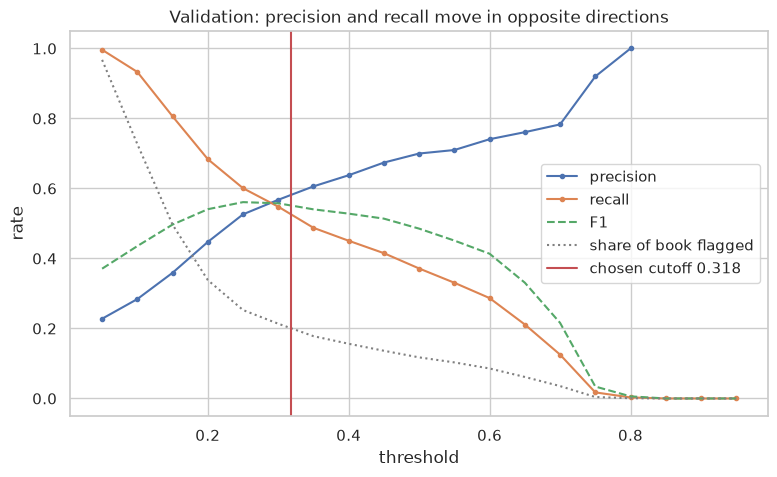

In [2]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sweep.threshold, sweep.precision, label='precision', marker='o', ms=3)
ax.plot(sweep.threshold, sweep.recall, label='recall', marker='o', ms=3)
ax.plot(sweep.threshold, sweep.f1, label='F1', ls='--')
ax.plot(sweep.threshold, sweep.flagged_rate, label='share of book flagged', ls=':', color='grey')
ax.axvline(cfg['threshold'], color='#c44e52', label=f"chosen cutoff {cfg['threshold']:.3f}")
ax.set_xlabel('threshold'); ax.set_ylabel('rate'); ax.legend()
ax.set_title('Validation: precision and recall move in opposite directions')
plt.show()

## Three candidate policies

1. **0.5** — the library default. It is the right cutoff only when a false positive and a
   false negative cost the same, which here they do not.
2. **Cost break-even at 10:1** — if a miss costs ten false alarms, expected cost is minimised
   at `cost_fp / (cost_fn + cost_fp)` = 0.0909. Mathematically correct, operationally useless.
3. **Review capacity** — flag the riskiest 20% of the book, on the assumption that is what the
   team can work. The 20% is an assumption, stated as one.

In [3]:
display(pol.round(4))
be = pol.iloc[1]
cap = pol.iloc[2]
half = pol.iloc[0]
print(f"the 10:1 break-even cutoff flags {be.flagged_rate:.1%} of the book -- "
      f"{be.tp + be.fp:,.0f} accounts for one team to call")
print(f"the 0.5 default flags {half.flagged_rate:.1%} and misses {half.fn:,.0f} defaulters")
print(f"the capacity cutoff flags {cap.flagged_rate:.1%}: {cap.precision:.1%} of those flagged "
      f"really default, and it catches {cap.recall:.1%} of all defaulters")

,policy,threshold,flagged_rate,precision,recall,f1,lift,tp,fp,fn,tn
0,library default (0.5),0.5000,0.1174,0.6999,0.3713,0.4852,3.1634,492,211,833,4453
1,cost break-even at 10:1 (0.0909),0.0909,0.7721,0.2714,0.9472,0.4219,1.2268,1255,3369,70,1295
2,review capacity (20% of the book),0.3176,0.2000,0.5776,0.5223,0.5486,2.6109,692,506,633,4158


the 10:1 break-even cutoff flags 77.2% of the book -- 4,624 accounts for one team to call
the 0.5 default flags 11.7% and misses 833 defaulters
the capacity cutoff flags 20.0%: 57.8% of those flagged really default, and it catches 52.2% of all defaulters


The cost argument and the capacity constraint point in opposite directions, and the binding
one wins. Expressing the policy as *"the worst 20%"* rather than as a fixed probability also
means it survives a refit: the queue stays the size the team can work even if the
probabilities shift.

What the bank gives up by capping the queue at 20% is visible in the recall column — roughly
half of all defaulters are not reviewed. That is the honest cost of the constraint, and the
number to take to whoever owns the staffing decision.

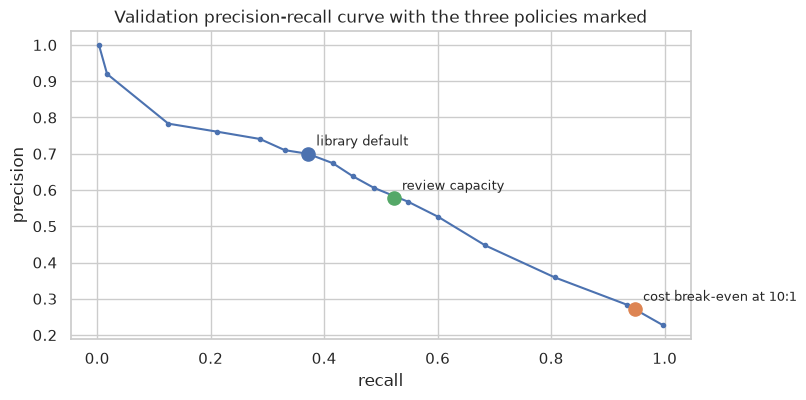

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sweep.recall, sweep.precision, marker='o', ms=3)
for _, row in pol.iterrows():
    ax.scatter(row.recall, row.precision, s=90, zorder=5)
    ax.annotate(row.policy.split(' (')[0], (row.recall, row.precision),
                textcoords='offset points', xytext=(6, 6), fontsize=9)
ax.set_xlabel('recall'); ax.set_ylabel('precision')
ax.set_title('Validation precision-recall curve with the three policies marked')
plt.show()

## SHAP — what the model is using

SHAP distributes a prediction across the features that produced it, in log-odds, relative to
the model's average output. Computed on 2,000 validation rows with `TreeExplainer`.

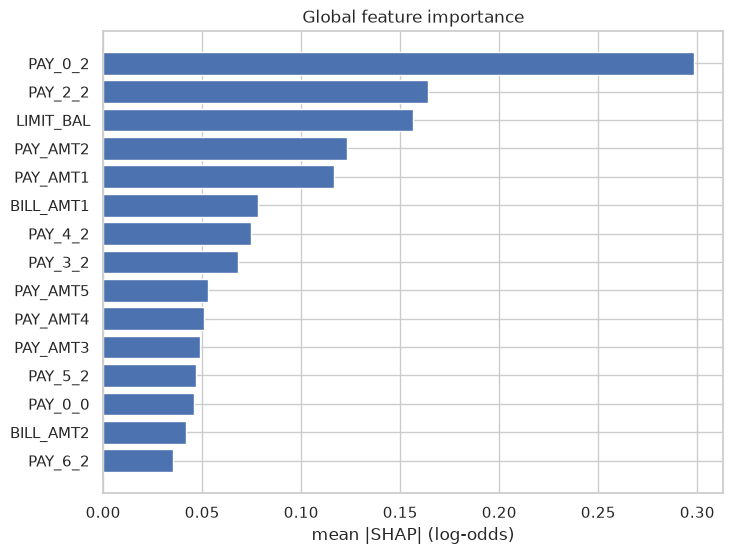

,feature,mean_abs_shap
0,PAY_0_2,0.2981
1,PAY_2_2,0.1641
2,LIMIT_BAL,0.1563
3,PAY_AMT2,0.1231
4,PAY_AMT1,0.1163
5,BILL_AMT1,0.0780
6,PAY_4_2,0.0747
7,PAY_3_2,0.0681
8,PAY_AMT5,0.0530
9,PAY_AMT4,0.0508


In [5]:
top = shap_global.head(15)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.feature[::-1], top.mean_abs_shap[::-1], color='#4c72b0')
ax.set_xlabel('mean |SHAP| (log-odds)')
ax.set_title('Global feature importance')
plt.show()
display(shap_global.head(15).round(4))

In [6]:
leader = shap_global.iloc[0]
pay_share = shap_global[shap_global.feature.str.startswith('PAY_') &
                        ~shap_global.feature.str.startswith('PAY_AMT')].mean_abs_shap.sum()
amt_share = shap_global[shap_global.feature.str.startswith('PAY_AMT')].mean_abs_shap.sum()
total = shap_global.mean_abs_shap.sum()
print(f"top feature: {leader.feature} at {leader.mean_abs_shap:.4f} mean |SHAP|")
print(f"repayment-status features together: {pay_share / total:.1%} of total attribution")
print(f"payment-amount features together:   {amt_share / total:.1%}")

top feature: PAY_0_2 at 0.2981 mean |SHAP|
repayment-status features together: 50.3% of total attribution
payment-amount features together:   25.6%


This agrees with the EDA rather than contradicting it, which is the first thing to check. The
single September repayment indicator dominates; the amounts actually paid come next; the
demographics are nowhere.

Being late *this* month is the dominant signal, and being late two months running is worse
than being late once — which is what a credit analyst would have told you, and is the reason
to trust it.

## Two individual customers

Global importance says what the model uses on average. A reviewer looking at one flagged
account needs the reason for *that* account.

In [7]:
for case in shap_local:
    print(f"=== {case['case']}: p(default) = {case['p_default']:.4f} "
          f"(model's average {case['base_rate_from_model']:.4f}) ===")
    display(pd.DataFrame(case['drivers']).round(4))

=== highest risk: p(default) = 0.8254 (model's average 0.1823) ===


,feature,shap
0,PAY_2_2,0.9911
1,PAY_0_3+,0.6077
2,PAY_3_2,0.3842
3,PAY_6_3+,0.2102
4,LIMIT_BAL,0.2052
5,PAY_AMT1,0.1872


=== lowest risk: p(default) = 0.0361 (model's average 0.1823) ===


,feature,shap
0,PAY_AMT2,-0.3683
1,PAY_AMT1,-0.2911
2,PAY_0_2,-0.2175
3,LIMIT_BAL,-0.1994
4,PAY_AMT5,-0.1420
5,BILL_AMT1,-0.1223


Positive SHAP pushes risk up, negative pushes it down, and the two cases are near-mirror
images: late repayment codes drive the risky one up, while sizeable recent payments drive the
safe one down. That is a sentence a reviewer can put in a case note, which is the whole point
of running SHAP rather than quoting an accuracy figure.